In [2]:
import os
base = '/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset'
print(os.listdir(base))

['Lung_Opacity.metadata.xlsx', 'Normal.metadata.xlsx', 'README.md.txt', 'COVID.metadata.xlsx', 'Normal', 'Lung_Opacity', 'Viral Pneumonia.metadata.xlsx', 'Viral Pneumonia', 'COVID']


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

classes = ['COVID', 'Normal', 'Lung_Opacity', 'Viral Pneumonia']

data = []
for c in classes:
    img_dir = os.path.join(base, c, 'images')
    for fname in os.listdir(img_dir):
        data.append({'filepath': os.path.join(img_dir, fname), 'label': c})

df = pd.DataFrame(data)
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)

datagen = ImageDataGenerator(rescale=1./255)

train_gen = datagen.flow_from_dataframe(
    train_df, x_col='filepath', y_col='label',
    target_size=(224, 224), batch_size=32, class_mode='categorical'
)

val_gen = datagen.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=(224, 224), batch_size=32, class_mode='categorical'
)

eval_gen = datagen.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=(224, 224), batch_size=32, class_mode='categorical',
    shuffle=False
)

Found 16932 validated image filenames belonging to 4 classes.
Found 4233 validated image filenames belonging to 4 classes.
Found 4233 validated image filenames belonging to 4 classes.


In [4]:
from tensorflow.keras.applications import VGG19, DenseNet121, ResNet50, MobileNetV2
from tensorflow.keras import layers, models, optimizers
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np
import seaborn as sns

def build_model(base_model_fn, input_shape=(224,224,3), num_classes=4):
    base_model = base_model_fn(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model, base_model

def train_and_finetune(model_name, base_model_fn, train_gen, val_gen,
                        epochs_fe=5, epochs_ft=5, unfreeze_layers=4):
    print(f"\n{'='*50}\nEntraînement : {model_name}\n{'='*50}")
    model, base_model = build_model(base_model_fn)

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    hist_fe = model.fit(train_gen, validation_data=val_gen, epochs=epochs_fe)

    base_model.trainable = True
    for layer in base_model.layers[:-unfreeze_layers]:
        layer.trainable = False

    model.compile(optimizer=optimizers.Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
    hist_ft = model.fit(train_gen, validation_data=val_gen, epochs=epochs_ft)

    history = {
        'accuracy': hist_fe.history['accuracy'] + hist_ft.history['accuracy'],
        'val_accuracy': hist_fe.history['val_accuracy'] + hist_ft.history['val_accuracy'],
        'loss': hist_fe.history['loss'] + hist_ft.history['loss'],
        'val_loss': hist_fe.history['val_loss'] + hist_ft.history['val_loss'],
        'switch_epoch': epochs_fe
    }
    return model, history

def plot_finetuning_curves(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history['accuracy'], label='Train Accuracy')
    axes[0].plot(history['val_accuracy'], label='Val Accuracy')
    axes[0].axvline(x=history['switch_epoch'], color='gray', linestyle='--', label='Début fine-tuning')
    axes[0].set_title(f'{model_name} - Accuracy'); axes[0].set_xlabel('Epochs'); axes[0].legend()

    axes[1].plot(history['loss'], label='Train Loss')
    axes[1].plot(history['val_loss'], label='Val Loss')
    axes[1].axvline(x=history['switch_epoch'], color='gray', linestyle='--', label='Début fine-tuning')
    axes[1].set_title(f'{model_name} - Loss'); axes[1].set_xlabel('Epochs'); axes[1].legend()

    plt.tight_layout()
    plt.savefig(f'{model_name}_finetuning_curve.png')
    plt.show()

def evaluate_model(model, eval_gen, model_name):
    eval_gen.reset()
    y_pred_probs = model.predict(eval_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = eval_gen.classes
    class_names = list(eval_gen.class_indices.keys())

    print(f"\nRapport de classification - {model_name}")
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
    plt.title(f'Matrice de confusion - {model_name}')
    plt.ylabel('Vrai label'); plt.xlabel('Label prédit')
    plt.savefig(f'{model_name}_confusion_matrix.png')
    plt.show()

    auc = roc_auc_score(y_true, y_pred_probs, multi_class='ovr')
    return {
        'model': model_name,
        'accuracy': report['accuracy'],
        'precision': report['weighted avg']['precision'],
        'recall': report['weighted avg']['recall'],
        'f1_score': report['weighted avg']['f1-score'],
        'auc': auc
    }

In [5]:
model_densenet, history_densenet = train_and_finetune(
    'DenseNet121', DenseNet121, train_gen, val_gen,
    epochs_fe=5, epochs_ft=5, unfreeze_layers=4
)


Entraînement : DenseNet121


I0000 00:00:1783697448.733415      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
  2/530 ━━━━━━━━━━━━━━━━━━━━ 27s 53ms/step - accuracy: 0.3438 - loss: 1.5242   

I0000 00:00:1783697483.125709     140 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


530/530 ━━━━━━━━━━━━━━━━━━━━ 244s 408ms/step - accuracy: 0.7778 - loss: 0.5805 - val_accuracy: 0.8375 - val_loss: 0.4285
Epoch 2/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 66s 124ms/step - accuracy: 0.8399 - loss: 0.4360 - val_accuracy: 0.8353 - val_loss: 0.4225
Epoch 3/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 68s 129ms/step - accuracy: 0.8526 - loss: 0.3982 - val_accuracy: 0.8653 - val_loss: 0.3631
Epoch 4/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 67s 126ms/step - accuracy: 0.8588 - loss: 0.3772 - val_accuracy: 0.8566 - val_loss: 0.3678
Epoch 5/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 64s 120ms/step - accuracy: 0.8655 - loss: 0.3642 - val_accuracy: 0.8642 - val_loss: 0.3493
Epoch 1/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 118s 178ms/step - accuracy: 0.7857 - loss: 0.6383 - val_accuracy: 0.8552 - val_loss: 0.4085
Epoch 2/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 63s 119ms/step - accuracy: 0.8519 - loss: 0.4167 - val_accuracy: 0.8618 - val_loss: 0.3768
Epoch 3/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 68s 128ms/step - accuracy: 0.8629 - loss: 0.3853 - val_accu

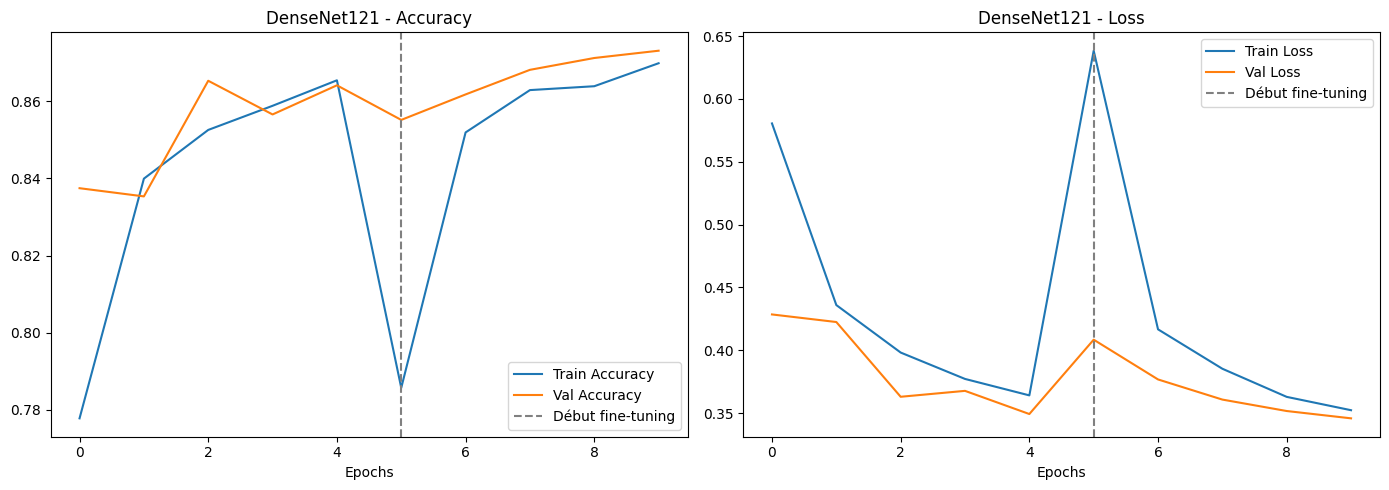

In [6]:
plot_finetuning_curves(history_densenet, 'DenseNet121')

133/133 ━━━━━━━━━━━━━━━━━━━━ 35s 177ms/step

Rapport de classification - DenseNet121
                 precision    recall  f1-score   support

          COVID       0.85      0.82      0.84       723
   Lung_Opacity       0.88      0.80      0.83      1203
         Normal       0.87      0.93      0.90      2038
Viral Pneumonia       0.95      0.94      0.94       269

       accuracy                           0.87      4233
      macro avg       0.89      0.87      0.88      4233
   weighted avg       0.87      0.87      0.87      4233



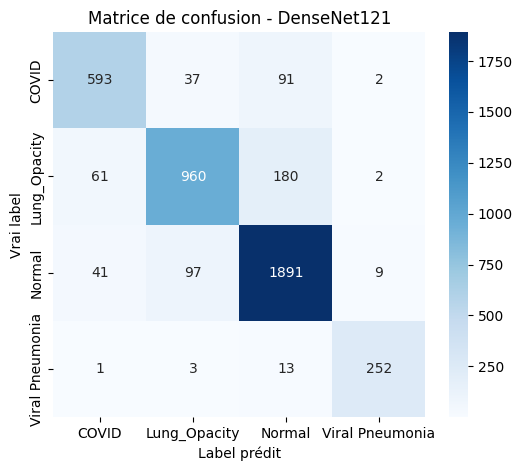

{'model': 'DenseNet121', 'accuracy': 0.8731396172927002, 'precision': 0.873248026921224, 'recall': 0.8731396172927002, 'f1_score': 0.8721762653024937, 'auc': np.float64(0.9730044730266209)}


In [7]:
metrics_densenet = evaluate_model(model_densenet, eval_gen, 'DenseNet121')
print(metrics_densenet)